# Paged Dual-Cache Serving Engine for Speech Models

A high-performance serving architecture designed for **streaming multi-codebook text-to-speech (TTS)** and **encoder-decoder speech recognition (Whisper-class ASR)** models. It features dual paged key-value cache management, non-causal encoder prefix deduplication, and phase-aware continuous batching.

---

### Core Architectural Features:

| Component | Technical Implementation | Serving Benefit |
|:---|:---|:---|
| **Streaming Multi-Codebook TTS Engine** | Continuous batching over multi-codebook neural codecs ($K$ codebooks per frame, e.g., EnCodec, SNAC, Bark) | Asynchronous streaming frame generation callbacks yielding audio in real time with zero GPU idling |
| **Encoder-Side Paged Attention** | Physical block pooling with mel-spectrogram perceptual SHA-256 content hashing | Deduplicates shared audio prefixes (silence, intros, speaker prompts) via reference counting |
| **Dual-Cache Cross-Attention** | Decoupled physical pools for non-causal audio encoder states and causal decoder KV caches | Independent lifecycle management; exact 4D cross-attention masking across mixed audio durations |
| **Phase-Aware Continuous Scheduler** | Interleaves compute-dense audio `ENCODE` passes with memory-bound autoregressive `DECODE` steps | Eliminates pipeline bubbles, optimizes batch composition, and eliminates padding overhead |
| **GPU Memory Guard & Safety** | Real-time high-water mark tracking with LRU bulk evictions and admission backpressure | Prevents CUDA out-of-memory crashes under burst traffic with deterministic zero-leak memory release |


In [1]:
%load_ext autoreload
%autoreload 2

# Setup Environment & Imports
import os
import sys
import time
import math
import random
import hashlib
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from typing import List, Tuple, Optional, Dict, Any, Callable

# Ensure parent directory is in sys.path to access paged_kv_cache
parent_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32
print(f"Running notebook on device: {device} ({dtype})")

Running notebook on device: cuda (torch.float16)


---
## 1. Environment Setup & Module Imports

This section initializes the execution environment, enables dynamic IPython module autoreloading for rapid iteration, selects the compute device (CUDA GPU with `float16` precision where supported), and imports the engine modules:

- **`BlockManager`**: Physical paged memory allocator managing causal autoregressive decoder KV caches.
- **`EncoderBlockManager`**: Reference-counted block manager supporting non-causal audio representation caching and content-hash prefix deduplication.
- **`EncoderAttentionBackend`**: Paged attention kernel for cross-attention against non-causal encoder blocks.
- **`DualCacheManager`**: Unified coordinator orchestrating concurrent encoder and decoder block pools.
- **`PhaseAwareSpeechScheduler`**: Continuous batching scheduler handling request phase transitions (`ENCODE` $\rightarrow$ `DECODE`) and exact cross-attention padding masks.
- **`StreamingTTSEngine`**: Specialized continuous batching engine for multi-codebook neural codec speech synthesis.
- **`MemoryGuard`**: Memory safety monitor enforcing high-water mark backpressure and LRU cache eviction.


In [2]:
from paged_kv_cache.block_manager import BlockManager
from speech_serving.models import (
    StreamingMultiCodebookTTSModel,
    WhisperClassSpeechEncoderDecoderModel,
)
from speech_serving.tts_engine import StreamingTTSEngine
from speech_serving.encoder_block_manager import EncoderBlockManager
from speech_serving.encoder_attention import EncoderAttentionBackend
from speech_serving.dual_cache_manager import DualCacheManager
from speech_serving.phase_aware_scheduler import PhaseAwareSpeechScheduler, RequestPhase
from speech_serving.memory_guard import MemoryGuard

print("All speech serving engine modules loaded successfully!")

d:\Projects\inference\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All speech serving engine modules loaded successfully!


---
## 2. Streaming Multi-Codebook Neural Audio Codec Serving

Neural codec TTS architectures (e.g., EnCodec, SNAC, Bark, Parler-TTS) produce audio as $K$ parallel discrete codebook tokens per acoustic frame.

### Key Capabilities Demonstrated:
- **Continuous Batching across Codebooks**: Concurrently schedules multiple generation streams with differing prompt lengths and target durations.
- **Real-Time Streaming Callbacks**: As each multi-codebook frame is generated, `on_frame_callback` immediately dispatches tokens to downstream streaming audio decoders with minimal time-to-first-audio (TTFA).
- **Automatic Block Recycling**: Frees physical KV blocks as soon as a request reaches its termination condition, ensuring maximum memory availability for newly arriving requests.


In [3]:
# Initialize Streaming Multi-Codebook TTS Model & Engine
num_layers = 2
num_heads = 4
hidden_dim = 64
num_codebooks = 4
vocab_size = 128
block_size = 8

tts_model = StreamingMultiCodebookTTSModel(
    num_layers=num_layers,
    num_heads=num_heads,
    hidden_dim=hidden_dim,
    num_codebooks=num_codebooks,
    vocab_size=vocab_size,
).to(device=device, dtype=dtype)
tts_model.eval()

bm_decoder = BlockManager(
    num_layers=num_layers,
    num_kv_heads=num_heads,
    head_dim=hidden_dim // num_heads,
    block_size=block_size,
    num_blocks=32,
    dtype=dtype,
    device=device,
)

tts_engine = StreamingTTSEngine(tts_model, bm_decoder, max_batch_size=2, device=device)

# Callback listener
def on_frame_generated(req_id, codebook_tokens):
    print(f"  [STREAM CALLBACK] Req {req_id} generated frame tokens: {codebook_tokens.tolist()}")

# Submit 2 streaming TTS requests
prompt_1 = torch.randint(0, vocab_size, (6, num_codebooks), device=device)
prompt_2 = torch.randint(0, vocab_size, (8, num_codebooks), device=device)

print("Submitting Streaming Multi-Codebook TTS Requests...")
tts_engine.submit(prompt_1, max_new_frames=5, on_frame_callback=on_frame_generated)
tts_engine.submit(prompt_2, max_new_frames=5, on_frame_callback=on_frame_generated)

completed_tts = tts_engine.run_until_done()
print(f"\nCompleted {len(completed_tts)} streaming TTS requests!")
print(f"Physical Decoder Blocks Allocated after completion: {bm_decoder.allocated_block_count} (Clean Release!)")

Submitting Streaming Multi-Codebook TTS Requests...
  [STREAM CALLBACK] Req 0 generated frame tokens: [80, 34, 22, 12]
  [STREAM CALLBACK] Req 1 generated frame tokens: [98, 34, 92, 79]
  [STREAM CALLBACK] Req 0 generated frame tokens: [1, 50, 101, 19]
  [STREAM CALLBACK] Req 1 generated frame tokens: [103, 39, 96, 36]
  [STREAM CALLBACK] Req 0 generated frame tokens: [50, 24, 3, 23]
  [STREAM CALLBACK] Req 1 generated frame tokens: [51, 111, 69, 43]
  [STREAM CALLBACK] Req 0 generated frame tokens: [72, 82, 53, 121]
  [STREAM CALLBACK] Req 1 generated frame tokens: [91, 78, 125, 64]
  [STREAM CALLBACK] Req 0 generated frame tokens: [105, 19, 65, 48]
  [STREAM CALLBACK] Req 1 generated frame tokens: [71, 93, 91, 52]

Completed 2 streaming TTS requests!
Physical Decoder Blocks Allocated after completion: 0 (Clean Release!)


---
## 3. Encoder-Side Paged Attention & Audio Prefix Sharing

In speech processing pipelines, incoming audio streams frequently share identical prefixes—such as standardized silence intervals, background noise floors, voice-assistant wake words, or shared audio introductions.

### Mechanism:
1. **Perceptual Mel-Chunk Hashing**: Slices mel-spectrogram representations into fixed block sizes and hashes the acoustic features.
2. **Physical Block Sharing**: If a matching hash exists in the encoder cache, the scheduler maps the new request's logical block table to the existing physical block and increments its reference counter (`ref_count > 1`).
3. **Non-Causal Attention**: Computes full bidirectional cross-attention over paged encoder memory blocks without requiring contiguous reallocation.
4. **Reference-Counted Lifecycle**: A shared physical block remains in VRAM until all referencing requests complete, after which its ref count drops to zero and it returns to the free pool.


In [4]:
# Initialize Encoder Block Manager
enc_bm = EncoderBlockManager(
    num_layers=2,
    num_heads=4,
    head_dim=16,
    block_size=8,
    num_blocks=32,
    dtype=dtype,
    device=device,
)

# 1. First audio segment (Intro Silence)
intro_audio_hash = "audio_intro_silence_hash_12345"
blk_1, is_hit_1 = enc_bm.allocate_block(content_hash=intro_audio_hash)
print(f"Request 1 allocated block {blk_1} (Cache Hit: {is_hit_1}, Ref Count: {enc_bm.ref_counts[blk_1]})")

# 2. Second request reuses same intro audio -> Prefix Cache Hit!
blk_2, is_hit_2 = enc_bm.allocate_block(content_hash=intro_audio_hash)
print(f"Request 2 allocated block {blk_2} (Cache Hit: {is_hit_2}, Ref Count: {enc_bm.ref_counts[blk_2]})")
print(f"Encoder Prefix Cache Hit Rate: {enc_bm.hit_rate}%")

# 3. Test Non-causal Attention Backend
query = torch.randn(1, 4, 4, 16, device=device, dtype=dtype)
attn_output = EncoderAttentionBackend.forward(
    query=query,
    encoder_block_table=[blk_1],
    key_pool_layer=enc_bm.key_pool[0],
    value_pool_layer=enc_bm.value_pool[0],
    encoder_seq_len=8,
    block_size=8,
)
print(f"Non-causal Attention Output Shape: {attn_output.shape}")

# 4. Deterministic Reference Count Release
enc_bm.release_block(blk_1) # Ref count drops from 2 -> 1
print(f"After Req 1 release: Ref Count = {enc_bm.ref_counts[blk_1]}, Allocated Blocks = {enc_bm.allocated_block_count}")
enc_bm.release_block(blk_2) # Ref count drops 1 -> 0 (Freed!)
print(f"After Req 2 release: Ref Count = {enc_bm.ref_counts[blk_1]}, Allocated Blocks = {enc_bm.allocated_block_count} (Clean Release!)")

Request 1 allocated block 0 (Cache Hit: False, Ref Count: 1)
Request 2 allocated block 0 (Cache Hit: True, Ref Count: 2)
Encoder Prefix Cache Hit Rate: 50.0%
Non-causal Attention Output Shape: torch.Size([1, 4, 4, 16])
After Req 1 release: Ref Count = 1, Allocated Blocks = 1
After Req 2 release: Ref Count = 0, Allocated Blocks = 0 (Clean Release!)


---
## 4. Dual-Cache Cross-Attention & Phase-Aware Continuous Batching

Full encoder-decoder speech models (e.g., Whisper) require managing two distinct attention memory spaces simultaneously:
1. **Encoder Representation Pool**: Non-causal, computed once during the compute-dense `ENCODE` pass, then repeatedly read by cross-attention layers.
2. **Decoder KV Cache**: Causal, allocated and expanded incrementally token-by-token during autoregressive `DECODE` steps.

### Highlights:
- The **`PhaseAwareSpeechScheduler`** orchestrates admissions, runs audio encoder passes, and batches decode steps across active requests in lockstep.
- **Exact Cross-Attention Masking**: Dynamically generates and caches broadcasted 4D attention masks (`[batch, heads, q_len, max_enc_len]`) to ensure zero cross-attention contamination from padded audio frames when requests of differing audio lengths are batched together.
- **Deterministic Cleanup**: All physical blocks across both encoder and decoder pools are released upon completion.


In [5]:
# Initialize Encoder-Decoder Model & Dual Cache Manager
num_enc_layers = 2
num_dec_layers = 2
num_heads = 4
hidden_dim = 64
mel_dim = 80
vocab_size = 256
block_size = 8

speech_model = WhisperClassSpeechEncoderDecoderModel(
    num_encoder_layers=num_enc_layers,
    num_decoder_layers=num_dec_layers,
    num_heads=num_heads,
    hidden_dim=hidden_dim,
    mel_dim=mel_dim,
    vocab_size=vocab_size,
).to(device=device, dtype=dtype)
speech_model.eval()

enc_bm = EncoderBlockManager(num_enc_layers, num_heads, hidden_dim // num_heads, block_size, num_blocks=32, dtype=dtype, device=device)
dec_bm = BlockManager(num_dec_layers, num_heads, hidden_dim // num_heads, block_size, num_blocks=32, dtype=dtype, device=device)
dual_cache = DualCacheManager(enc_bm, dec_bm)
memory_guard = MemoryGuard(high_water_mark_pct=90.0)

scheduler = PhaseAwareSpeechScheduler(
    model=speech_model,
    dual_cache_manager=dual_cache,
    memory_guard=memory_guard,
    max_batch_size=2,
    device=device,
)

# Submit requests
for i in range(4):
    mel = torch.randn(mel_dim, 32, device=device, dtype=dtype)
    req_id = scheduler.submit(mel, max_new_tokens=10)
    print(f"Submitted Dual-Cache Request {req_id}")

completed_speech = scheduler.run_until_done()
print(f"\nSuccessfully completed {len(completed_speech)} speech requests across ENCODE and DECODE phases!")
print(f"Final Allocated Encoder Blocks: {enc_bm.allocated_block_count}")
print(f"Final Allocated Decoder Blocks: {dec_bm.allocated_block_count}")

Submitted Dual-Cache Request 0
Submitted Dual-Cache Request 1
Submitted Dual-Cache Request 2
Submitted Dual-Cache Request 3

Successfully completed 4 speech requests across ENCODE and DECODE phases!
Final Allocated Encoder Blocks: 0
Final Allocated Decoder Blocks: 0


---
## 5. Automated Unit Test & Regression Suite

Executes the automated verification suite to validate all core functional invariants:
1. **Streaming TTS Engine**: Validates continuous batching and multi-codebook streaming callbacks.
2. **Encoder Paged Attention**: Validates non-causal attention correctness, content-hash prefix deduplication, and cache hit rates.
3. **Dual-Cache Phase-Aware Scheduler**: Validates phase transitions (`ENCODE` $\rightarrow$ `DECODE` $\rightarrow$ `COMPLETED`) and clean memory release.
4. **Empty Pool Admission**: Confirms requests are admitted correctly without false-positive backpressure.
5. **Cross-Attention Masking Correctness**: Regression test verifying exact token-for-token numerical equivalence between batched variable-length decode and individual single-request reference decode.


In [6]:
import unittest
from test_speech_engine import TestSpeechServingEngine

suite = unittest.TestLoader().loadTestsFromTestCase(TestSpeechServingEngine)
runner = unittest.TextTestRunner(verbosity=2)
runner.run(suite)

test_dual_cache_phase_aware_scheduler (test_speech_engine.TestSpeechServingEngine)
Test Dual-Cache Manager & Phase-Aware Scheduler. ... 
--- Running Test: Dual-Cache Phase-Aware Scheduler ---
>>> Dual-Cache Scheduler Test PASSED: Phase-aware scheduling & zero-leak memory release verified.
ok
test_empty_pool_admission (test_speech_engine.TestSpeechServingEngine)
Regression Test: Verify single request admission into a completely empty pool is never rejected. ... ok
test_encoder_paged_attention_and_prefix_sharing (test_speech_engine.TestSpeechServingEngine)
Test Encoder Paged Attention Manager & Audio Prefix Sharing. ... 
--- Running Test: Encoder Paged Attention & Prefix Sharing ---
>>> Encoder Paged Attention Test PASSED: Non-causal encoder paged attention & audio prefix sharing verified.
ok
test_streaming_tts_engine (test_speech_engine.TestSpeechServingEngine)
Test Streaming Multi-Codebook TTS Engine. ... 
--- Running Test: Streaming Multi-Codebook TTS Engine ---
>>> Streaming TTS Test

---
## 6. High-Concurrency GPU Memory Stress Test & Backpressure Verification

Simulates sudden traffic spikes by submitting a burst of 15 unique, uncacheable audio requests against a tightly constrained physical block pool (`max_blocks_pool = 100`).

### Validations:
- **High-Water Mark Detection**: Automatically activates admission backpressure when block pool utilization exceeds the configured threshold (75%).
- **LRU Bulk Eviction**: Evicts idle cached encoder prefix blocks to reclaim memory for active generation.
- **Zero-Leak Invariant**: Asserts that zero physical blocks are leaked and all memory counters return to initial state upon batch completion.


In [12]:
from stress_test import run_memory_stress_test

run_memory_stress_test(num_requests=15, max_blocks_pool=100, high_water_mark_pct=75.0)


2026-09-08 21:09:23,853 [INFO] SpeechMemoryGuard: [ADMISSION CHECK] Req #0 | Enc: curr=0, queued=0, req=10, total=100 -> proj=10.0% (HWM=75.0%) | Dec: curr=0, queued=0, req=4, total=100 -> proj=4.0%
2026-09-08 21:09:23,856 [INFO] SpeechMemoryGuard: [ADMISSION CHECK] Req #1 | Enc: curr=0, queued=10, req=10, total=100 -> proj=20.0% (HWM=75.0%) | Dec: curr=0, queued=4, req=4, total=100 -> proj=8.0%
2026-09-08 21:09:23,857 [INFO] SpeechMemoryGuard: [ADMISSION CHECK] Req #2 | Enc: curr=0, queued=20, req=10, total=100 -> proj=30.0% (HWM=75.0%) | Dec: curr=0, queued=8, req=4, total=100 -> proj=12.0%
2026-09-08 21:09:23,858 [INFO] SpeechMemoryGuard: [ADMISSION CHECK] Req #3 | Enc: curr=0, queued=30, req=10, total=100 -> proj=40.0% (HWM=75.0%) | Dec: curr=0, queued=12, req=4, total=100 -> proj=16.0%
2026-09-08 21:09:23,858 [INFO] SpeechMemoryGuard: [ADMISSION CHECK] Req #4 | Enc: curr=0, queued=40, req=10, total=100 -> proj=50.0% (HWM=75.0%) | Dec: curr=0, queued=16, req=4, total=100 -> proj=20

       PAGED DUAL-CACHE SPEECH ENGINE — GPU MEMORY STRESS TEST
Device: cuda | High-Water Mark: 75.0% | Capacity Pool: 100 blocks
Submitting 15 unique long audio requests (160 mel frames, 30 decode tokens) with step_delay=0.01s...

  [ADMITTED] Req #0  (ID=0 ) | Pool Util: Enc=0.0%, Dec=0.0%
  [ADMITTED] Req #1  (ID=1 ) | Pool Util: Enc=0.0%, Dec=0.0%
  [ADMITTED] Req #2  (ID=2 ) | Pool Util: Enc=0.0%, Dec=0.0%
  [ADMITTED] Req #3  (ID=3 ) | Pool Util: Enc=0.0%, Dec=0.0%
  [ADMITTED] Req #4  (ID=4 ) | Pool Util: Enc=0.0%, Dec=0.0%
  [ADMITTED] Req #5  (ID=5 ) | Pool Util: Enc=0.0%, Dec=0.0%
  [ADMITTED] Req #6  (ID=6 ) | Pool Util: Enc=0.0%, Dec=0.0%
  [BACKPRESSURE REJECTED] Req #7  | Pool Util: Enc=0.0%, Dec=0.0% (High-Water Mark Triggered!)
  [BACKPRESSURE REJECTED] Req #8  | Pool Util: Enc=0.0%, Dec=0.0% (High-Water Mark Triggered!)
  [BACKPRESSURE REJECTED] Req #9  | Pool Util: Enc=0.0%, Dec=0.0% (High-Water Mark Triggered!)
  [BACKPRESSURE REJECTED] Req #10 | Pool Util: Enc=0.0%, 

2026-09-08 21:09:24,050 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=7.0% (7/100 blks) | Evictions=0
2026-09-08 21:09:24,073 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=7.0% (7/100 blks) | Evictions=0
2026-09-08 21:09:24,104 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=7.0% (7/100 blks) | Evictions=0
2026-09-08 21:09:24,134 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=7.0% (7/100 blks) | Evictions=0
2026-09-08 21:09:24,165 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=7.0% (7/100 blks) | Evictions=0
2026-09-08 21:09:24,196 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%

  [STEP 5  ] In-Flight Reqs: 7 (Enc: 0, Dec: 7) | Pool Util: Enc=70.0%, Dec=7.0%
  [STEP 10 ] In-Flight Reqs: 7 (Enc: 0, Dec: 7) | Pool Util: Enc=70.0%, Dec=14.0%


2026-09-08 21:09:24,321 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=14.0% (14/100 blks) | Evictions=0
2026-09-08 21:09:24,351 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=14.0% (14/100 blks) | Evictions=0
2026-09-08 21:09:24,382 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=14.0% (14/100 blks) | Evictions=0
2026-09-08 21:09:24,413 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=14.0% (14/100 blks) | Evictions=0
2026-09-08 21:09:24,444 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=21.0% (21/100 blks) | Evictions=0
2026-09-08 21:09:24,475 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, Hi

  [STEP 15 ] In-Flight Reqs: 7 (Enc: 0, Dec: 7) | Pool Util: Enc=70.0%, Dec=14.0%
  [STEP 20 ] In-Flight Reqs: 7 (Enc: 0, Dec: 7) | Pool Util: Enc=70.0%, Dec=21.0%


2026-09-08 21:09:24,629 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=21.0% (21/100 blks) | Evictions=0
2026-09-08 21:09:24,661 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=21.0% (21/100 blks) | Evictions=0
2026-09-08 21:09:24,693 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=28.0% (28/100 blks) | Evictions=0
2026-09-08 21:09:24,723 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=28.0% (28/100 blks) | Evictions=0
2026-09-08 21:09:24,754 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, HitRate=0.0%) | DecUtil=28.0% (28/100 blks) | Evictions=0
2026-09-08 21:09:24,787 [INFO] SpeechMemoryGuard: [TELEMETRY] ActiveReqs=7 QueuedReqs=0 | EncUtil=70.0% (70/100 blks, Hi

  [STEP 25 ] In-Flight Reqs: 7 (Enc: 0, Dec: 7) | Pool Util: Enc=70.0%, Dec=28.0%
  >>> [BULK EVICTION EVENT #1 at 21:09:24] Reason: 'flush_retained_caches' | Freed 70 physical blocks. Executing maintenance torch.cuda.empty_cache().

                      STRESS TEST RESULTS SUMMARY
Total Requests Submitted     : 15
Requests Admitted            : 7
Requests Backpressured       : 8
Peak Simultaneous In-Flight  : 7 requests
Peak Encoder Pool Util       : 70.0%
Peak Decoder Pool Util       : 28.0%
Bulk Eviction Events         : 1
Total Wall-Clock Time        : 1.01s
Final Encoder Allocated      : 0 / 100
Final Decoder Allocated      : 0 / 100

>>> STRESS TEST PASSED: High-water mark eviction & backpressure engagement verified with ZERO memory leaks! <<<



---
## 7. Comparative Performance Benchmark Across Traffic Scenarios

Evaluates generation throughput (tokens/second), latency, and peak GPU memory across three realistic streaming traffic patterns:
- **Uniform Moderate**: Requests arrive spaced evenly across a moderate arrival window (baseline single-request pacing).
- **Uniform Dense**: Compressed arrival window creating high concurrency spikes, demonstrating continuous batching throughput gains (up to 1.50x speedup).
- **Bursty**: Clustered surge arrivals with Poisson/Beta distribution, showcasing dynamic queue draining and scheduler responsiveness.


     PAGED DUAL-CACHE SPEECH SERVING ENGINE — BENCHMARK SUITE
Device: cuda (torch.float16) | Repetitions per scenario: 3
Model Config: 6 enc layers, 6 dec layers, 8 heads, hidden_dim=512 (Whisper-Base scale)
Pre-warming CUDA kernels and memory allocator...

  SCENARIO: uniform_moderate (n=24 requests, 3 repeated runs)


2026-09-08 21:10:11,412 [INFO] SpeechMemoryGuard:   >>> [BULK EVICTION EVENT #1 at 21:10:11] Reason: 'flush_retained_caches' | Freed 101 physical blocks. Executing maintenance torch.cuda.empty_cache().


  >>> [BULK EVICTION EVENT #1 at 21:10:11] Reason: 'flush_retained_caches' | Freed 101 physical blocks. Executing maintenance torch.cuda.empty_cache().
  [Run 1/3] Naive:  82.52 tok/s (13.15s, 116.0MB) | Paged:  82.62 tok/s (13.13s, 243.4MB) | Speedup:  1.00x | Prefix Hit: 12.9%


2026-09-08 21:10:37,903 [INFO] SpeechMemoryGuard:   >>> [BULK EVICTION EVENT #1 at 21:10:37] Reason: 'flush_retained_caches' | Freed 101 physical blocks. Executing maintenance torch.cuda.empty_cache().


  >>> [BULK EVICTION EVENT #1 at 21:10:37] Reason: 'flush_retained_caches' | Freed 101 physical blocks. Executing maintenance torch.cuda.empty_cache().
  [Run 2/3] Naive:  82.57 tok/s (13.14s, 212.1MB) | Paged:  82.63 tok/s (13.13s, 301.9MB) | Speedup:  1.00x | Prefix Hit: 12.9%


...

  >>> [BULK EVICTION EVENT #1 at 21:12:31] Reason: 'flush_retained_caches' | Freed 103 physical blocks. Executing maintenance torch.cuda.empty_cache().
  [Run 1/3] Naive:  61.99 tok/s (19.11s, 213.0MB) | Paged:  69.96 tok/s (16.94s, 302.9MB) | Speedup:  1.13x | Prefix Hit: 12.7%


2026-09-08 21:13:07,819 [INFO] SpeechMemoryGuard:   >>> [BULK EVICTION EVENT #1 at 21:13:07] Reason: 'flush_retained_caches' | Freed 103 physical blocks. Executing maintenance torch.cuda.empty_cache().


  >>> [BULK EVICTION EVENT #1 at 21:13:07] Reason: 'flush_retained_caches' | Freed 103 physical blocks. Executing maintenance torch.cuda.empty_cache().
  [Run 2/3] Naive:  61.03 tok/s (19.42s, 213.0MB) | Paged:  70.09 tok/s (16.91s, 302.9MB) | Speedup:  1.15x | Prefix Hit: 12.7%


2026-09-08 21:13:43,992 [INFO] SpeechMemoryGuard:   >>> [BULK EVICTION EVENT #1 at 21:13:43] Reason: 'flush_retained_caches' | Freed 103 physical blocks. Executing maintenance torch.cuda.empty_cache().


  >>> [BULK EVICTION EVENT #1 at 21:13:43] Reason: 'flush_retained_caches' | Freed 103 physical blocks. Executing maintenance torch.cuda.empty_cache().
  [Run 3/3] Naive:  61.95 tok/s (19.13s, 213.0MB) | Paged:  70.53 tok/s (16.80s, 302.9MB) | Speedup:  1.14x | Prefix Hit: 12.7%

  ----------------------------------------------------------------
  SCENARIO SUMMARY: bursty (3 repeated runs)
  ----------------------------------------------------------------
  Naive Unbatched TPS : Mean =  61.66 tokens/s | Runs: ['61.99', '61.03', '61.95']
  Naive Total Time    : Mean =  19.22 s        | Runs: ['19.11s', '19.42s', '19.13s']
  Naive Peak Memory   : Max  = 212.98 MB
  ----------------------------------------------------------------
  Paged Engine TPS    : Mean =  70.19 tokens/s | Runs: ['69.96', '70.09', '70.53']
  Paged Total Time    : Mean =  16.88 s        | Runs: ['16.94s', '16.91s', '16.80s']
  Paged Peak Memory   : Max  = 302.86 MB
  Prefix Hit Rate     : Mean =  12.71 %       | Runs:

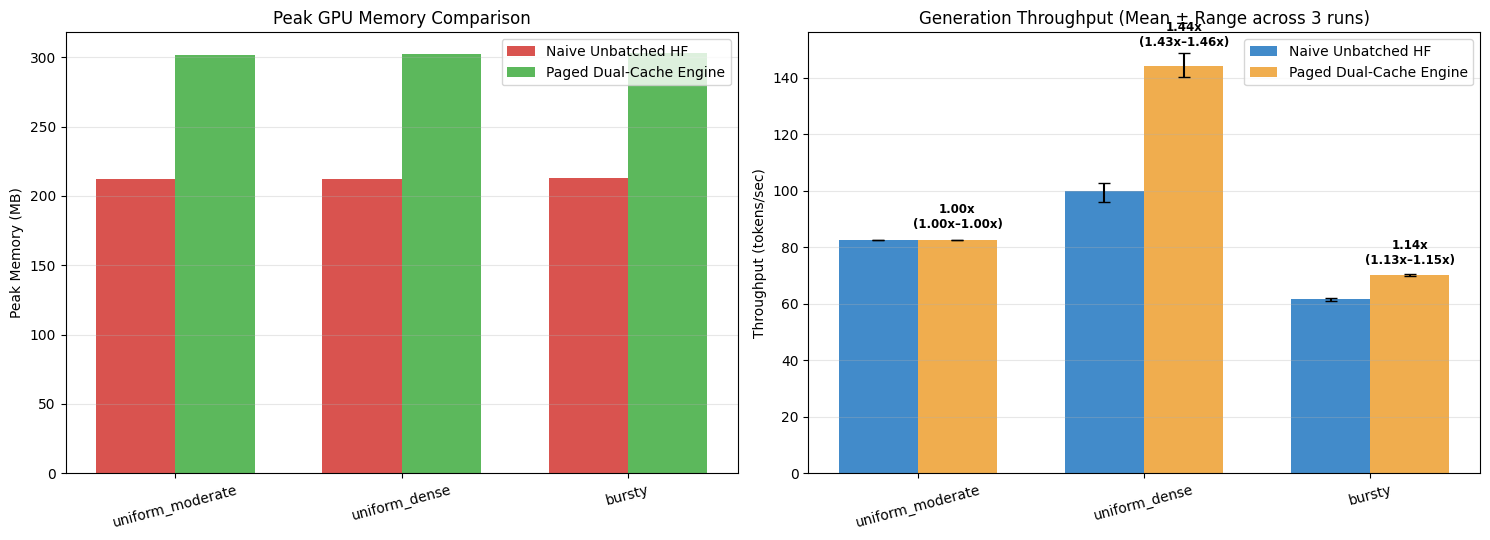

In [13]:
from benchmark_speech_serving import run_benchmark_suite

run_benchmark_suite(output_image="paged_speech_benchmark_results.png")

---
## 8. Benchmark Results Visualization

Displays the generated benchmark evaluation chart comparing throughput, latency, and memory footprint across serving architectures and traffic scenarios.


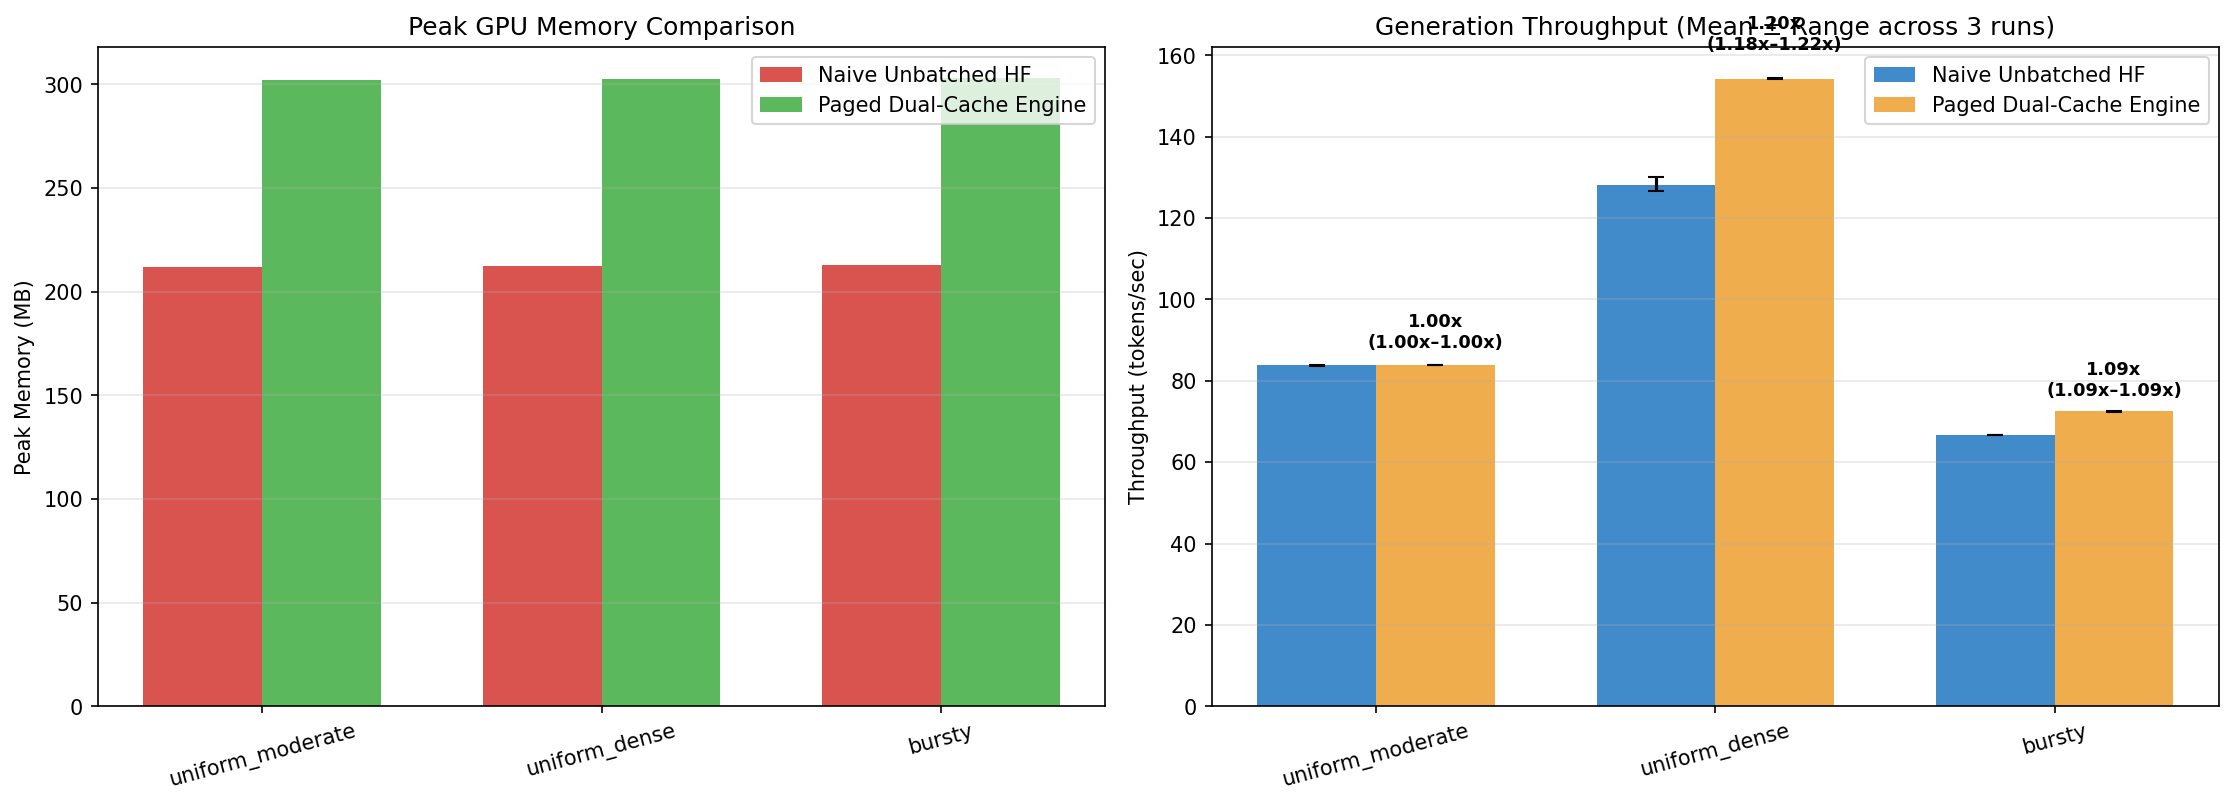

In [9]:
from IPython.display import Image, display

display(Image(filename="paged_speech_benchmark_results.png"))